# Cameron Peak and East Troublesome Fire Burn Severity
## Burn Severity

- **Objective:**
For this notebook, burn severity is mapped for the 2020 Cameron Peak and East Troublesome fires from the HLS summer composites made in 01_data_download. Differenced Normalized Burn Ratio (dNBR) is calculated from the summers before and after the fires, and split into burn severity classes with the Key and Benson (2006) thresholds.

- **Objective goals:**
    - Calculate dNBR from the 2019 and 2021 summer NBR composites
    - Classify dNBR into the Key and Benson burn severity classes
    - Map the burn severity classes and total the area in each class
    - Save dNBR and the burn severity classes for the rest of the analysis

---

### Methodology

#### 1. Calculate dNBR
- Calculate dNBR from the 2019 and 2021 NBR composites

#### 2. Classify dNBR
- Split dNBR into the six Key and Benson classes

#### 3. Map the Burn Severity
- Histogram of dNBR in each class
- Burn severity maps
- Area in each class

#### 4. Save the Results
- Save dNBR, the burn severity classes, and the area in each class

#### 5. Summary
- Sum up how severely each fire burned

# Libraries

In [1]:
### file paths, OS operations, utilities
import os
import pathlib

### data handling
import numpy as np
import pandas as pd
import geopandas as gpd

### rasters
import rioxarray as rxr
import xarray as xr
from rasterio.features import geometry_mask

### visualization
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Primary Directory

In [2]:
### set up root file path
# Walk up from the current directory to find the repo root (contains .git)
_cwd = pathlib.Path(os.getcwd()).resolve()
repo_root = next(
    (p for p in [_cwd] + list(_cwd.parents) if (p / '.git').exists()),
    _cwd
)
os.chdir(repo_root)

data_dir = os.path.join(repo_root, 'data')
os.makedirs(data_dir, exist_ok=True)

print('Repo root:', repo_root)

Repo root: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity


# Secondary Directories

In [3]:
### set a directory for the burn severity results
severity_dir = os.path.join(data_dir, 'severity')
os.makedirs(severity_dir, exist_ok=True)

# Load the Downloaded Data
This is the Universal Calls cell from 01_data_download, which loads the data saved there.

In [4]:
### root dir
data_dir = os.path.join(repo_root, 'data')

### fire names used in the file names
fire_keys = ["cameron_peak", "east_troublesome"]


### PERIMETERS AND STUDY AREAS
perimeters_gdf = gpd.read_file(os.path.join(data_dir, 'perimeters', 'nifc_perimeters.gpkg'))
study_area_gdf = gpd.read_file(os.path.join(data_dir, 'perimeters', 'study_areas.gpkg'))


### MTBS
### fire records and dNBR thresholds
mtbs_fires_df = pd.read_csv(os.path.join(data_dir, 'mtbs', 'mtbs_fires.csv'))

### MTBS boundaries
mtbs_gdf = gpd.read_file(os.path.join(data_dir, 'mtbs', 'mtbs_boundaries.gpkg'))

### MTBS burn severity maps
mtbs_paths = {}
for fire in fire_keys:
    mtbs_paths[fire] = os.path.join(data_dir, 'mtbs', 'mtbs_' + fire + '_2020.tif')


### WATERSHEDS
huc12_gdf = gpd.read_file(os.path.join(data_dir, 'watersheds', 'huc12.gpkg'))


### WUI
wui_path = os.path.join(data_dir, 'wui', 'wui_CO_2019_clip.tif')


### HLS COMPOSITES
### e.g. hls_paths[("cameron_peak", 2021)]["nbr"]
hls_paths = {}
for fire in fire_keys:
    for year in range(2019, 2027):
        fire_hls_dir = os.path.join(data_dir, 'hls', fire)
        file_start = "hls_" + fire + "_" + str(year)
        hls_paths[(fire, year)] = {
            "nbr": os.path.join(fire_hls_dir, file_start + "_nbr.tif"),
            "ndvi": os.path.join(fire_hls_dir, file_start + "_ndvi.tif"),
            "count": os.path.join(fire_hls_dir, file_start + "_count.tif"),
            "scenes": os.path.join(fire_hls_dir, file_start + "_scenes.csv"),
        }

### Settings
The pre-fire and post-fire years follow the summer window in 01_data_download: 2019 is the summer before both fires, and 2021 is the first summer after.

In [5]:
### pre-fire and post-fire summer composites
pre_fire_year = 2019
post_fire_year = 2021

### projected coordinate system of the rasters: UTM zone 13N (meters)
utm_crs = "EPSG:32613"

### pixel size of the HLS data (meters)
cell_size = 30

### square meters in one acre
m2_per_acre = 4046.8564224

# 1. dNBR
dNBR is the difference in NBR between the summer before the fires (2019) and the summer after (2021). It is multiplied by 1000, which is the scale burn severity thresholds use.

dNBR = (NBR 2019 - NBR 2021) x 1000

Healthy vegetation has a high NBR and burned areas have a low NBR, so the more severe the fire, the bigger the drop. Dense forest has more to lose than open forest or grassland, so the same fire effects give a bigger dNBR in dense forest.

In [6]:
### create a function to calculate dNBR for one fire
def calculate_dnbr(fire):
    """
    Calculate dNBR for one fire from the pre-fire and post-fire NBR composites

    Args:
    fire (str): fire name, e.g. "cameron_peak"

    Returns:
    xarray.DataArray: dNBR, NaN where either composite has no clear looks
    """

    ### open the pre-fire and post-fire NBR composites
    nbr_pre = rxr.open_rasterio(hls_paths[(fire, pre_fire_year)]["nbr"], masked=True).squeeze()
    nbr_post = rxr.open_rasterio(hls_paths[(fire, post_fire_year)]["nbr"], masked=True).squeeze()

    ### dNBR: the drop in NBR, x 1000
    return (nbr_pre - nbr_post) * 1000

In [7]:
### calculate dNBR for both fires
dnbr = {}

for fire in fire_keys:
    dnbr[fire] = calculate_dnbr(fire)

### Make the perimeter masks
Burn severity areas are only counted inside each NIFC perimeter, so a mask of the pixels inside each perimeter is made on the 30m grid.

In [8]:
### project the perimeters to UTM zone 13N to match the rasters
perimeters_utm = perimeters_gdf.to_crs(utm_crs)

### make a True/False mask of the pixels inside each fire perimeter
inside_masks = {}

for fire in fire_keys:
    perimeter = perimeters_utm[perimeters_utm["fire"] == fire]
    inside_masks[fire] = geometry_mask(perimeter.geometry, out_shape=dnbr[fire].shape, transform=dnbr[fire].rio.transform(), invert=True)

    ### check how much of the fire has no clear pixels in 2019 or 2021 (clouds, water, snow, and so on)
    no_data = np.isnan(dnbr[fire].values[inside_masks[fire]]).mean() * 100
    print(fire + ": " + str(round(no_data, 2)) + "% of the area inside the perimeter has no data")

cameron_peak: 0.22% of the area inside the perimeter has no data
east_troublesome: 0.15% of the area inside the perimeter has no data


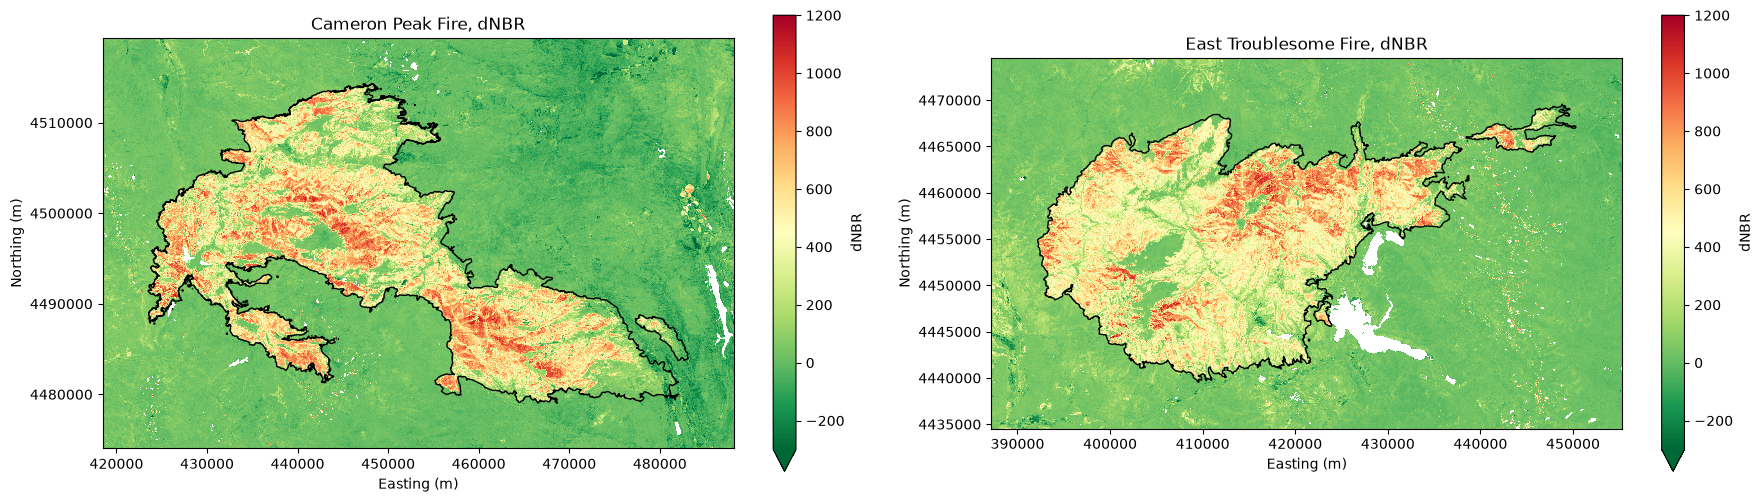

In [9]:
### plot dNBR for both fires
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for ax, fire in zip(axes, fire_keys):

    ### plot dNBR
    dnbr_plot = dnbr[fire].plot(ax=ax, cmap="RdYlGn_r", vmin=-300, vmax=1200, cbar_kwargs={"shrink": 0.8})
    dnbr_plot.colorbar.set_label("dNBR")

    ### add the fire perimeter
    perimeters_utm[perimeters_utm["fire"] == fire].boundary.plot(ax=ax, color="black", linewidth=1)

    ax.set_aspect("equal")
    ax.ticklabel_format(style="plain")
    ax.set_title(fire.replace("_", " ").title() + " Fire, dNBR")
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")

plt.tight_layout()
plt.show()

Figure 1: dNBR for each study area, with the NIFC perimeter in black. Red pixels had the biggest drop in NBR from 2019 to 2021.

# 2. Burn Severity Classes
dNBR is split into six classes at the Key and Benson (2006) thresholds, the most widely used dNBR thresholds:

| Class | dNBR |
|---|---|
| Enhanced regrowth | below -100 |
| Unburned | -100 to 100 |
| Low | 100 to 270 |
| Moderate-low | 270 to 440 |
| Moderate-high | 440 to 660 |
| High | 660 and above |

Key and Benson was chosen after reviewing the burn severity research. It is a well documented standard, made for the USDA Forest Service's FIREMON fire monitoring program, and it uses the same thresholds for every fire, so the results can be repeated and compared with other studies. The result is compared with the official MTBS burn severity maps in 03_mtbs_comparison.

In [10]:
### Key and Benson classes: (class name, dNBR value where the class starts), from lowest to highest
kb_classes = [("Enhanced regrowth", -np.inf), ("Unburned", -100), ("Low", 100),
              ("Moderate-low", 270), ("Moderate-high", 440), ("High", 660)]
class_names = [name for name, start in kb_classes]

### map colors for each class (the MTBS colors from 01_data_download, with blue for low and orange for moderate-high)
class_colors = {
    "Enhanced regrowth": "#7fff00",
    "Unburned": "#006400",
    "Low": "#227aff",
    "Moderate-low": "#ffff00",
    "Moderate-high": "#ff9205",
    "High": "#ff0000",
}

### Define the classify function
Each pixel gets the number of the highest class it reaches (1 for Enhanced regrowth, 2 for Unburned, and so on up to 6 for High). Pixels with no data get 0.

In [11]:
### create a function to sort dNBR into classes
def classify(dnbr_da, classes):
    """
    Sort each pixel of dNBR into classes

    Args:
    dnbr_da (xarray.DataArray): dNBR
    classes (list): (class name, dNBR value where the class starts), from lowest to highest

    Returns:
    xarray.DataArray: class number for each pixel (1 = first class), 0 where there is no data
    """

    ### start with 0 (no data) everywhere
    classes_da = xr.zeros_like(dnbr_da, dtype="uint8")

    ### give each pixel the number of the highest class it reaches
    for number, (name, start) in enumerate(classes, start=1):
        classes_da = xr.where(dnbr_da >= start, number, classes_da)

    return classes_da.astype("uint8")

In [12]:
### classify dNBR for both fires
severity_classes = {}

for fire in fire_keys:
    severity_classes[fire] = classify(dnbr[fire], kb_classes)

# 3. Burn Severity Maps

### Create a histogram showing dNBR in each class

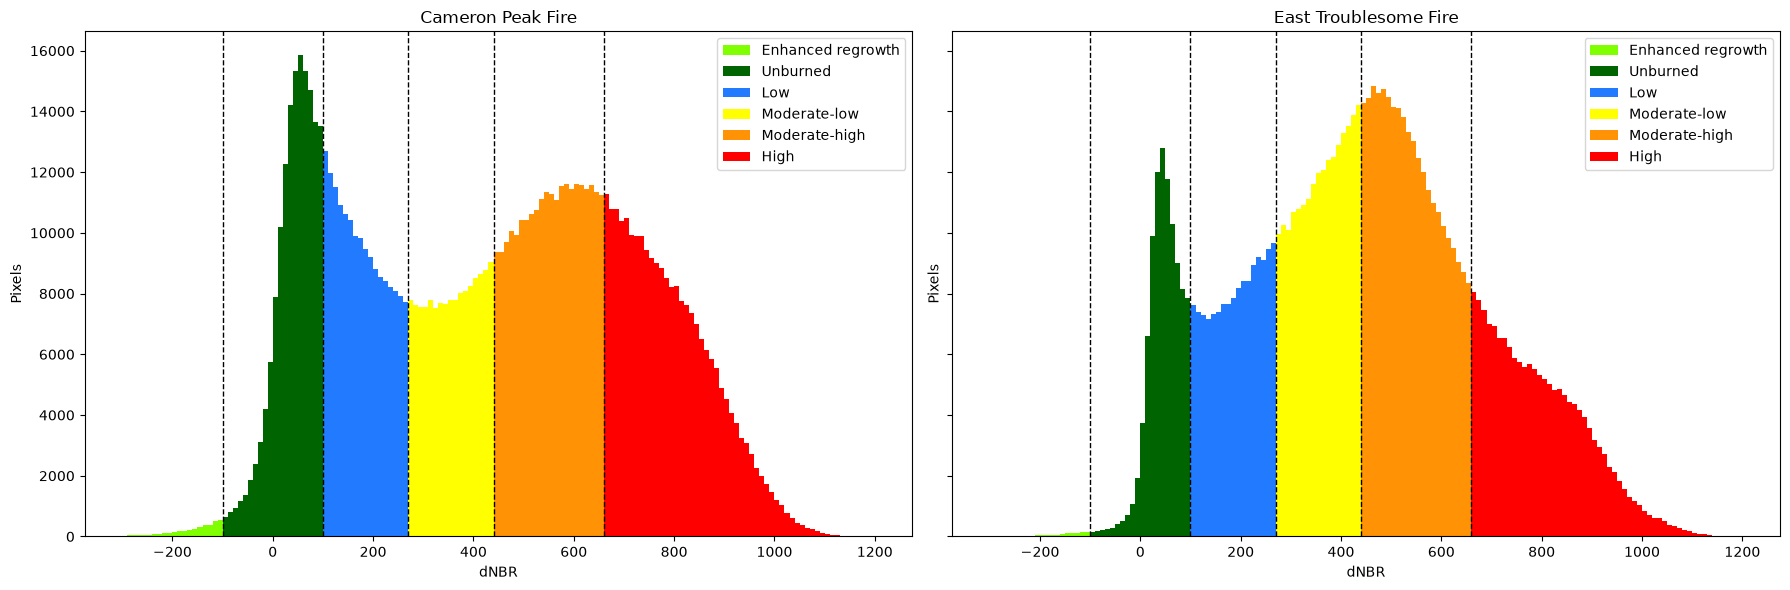

In [13]:
### dNBR value where each class starts
starts = [start for name, start in kb_classes]

### plot a histogram of dNBR inside each perimeter, colored by class
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

for ax, fire in zip(axes, fire_keys):

    ### dNBR and class of each pixel inside the perimeter
    values = dnbr[fire].values[inside_masks[fire]]
    classes = severity_classes[fire].values[inside_masks[fire]]

    ### a histogram for each class, in its color
    for number, name in enumerate(class_names, start=1):
        ax.hist(values[classes == number], bins=150, range=(-300, 1200), color=class_colors[name], label=name)

    ### add a line where each class starts
    for start in starts[1:]:
        ax.axvline(start, color="black", linestyle="--", linewidth=1)

    ax.set_title(fire.replace("_", " ").title() + " Fire")
    ax.set_xlabel("dNBR")
    ax.set_ylabel("Pixels")
    ax.legend()

plt.tight_layout()
plt.show()

Figure 2: dNBR inside each perimeter, colored by Key and Benson class, with a dashed line where each class starts.

### Burn severity maps

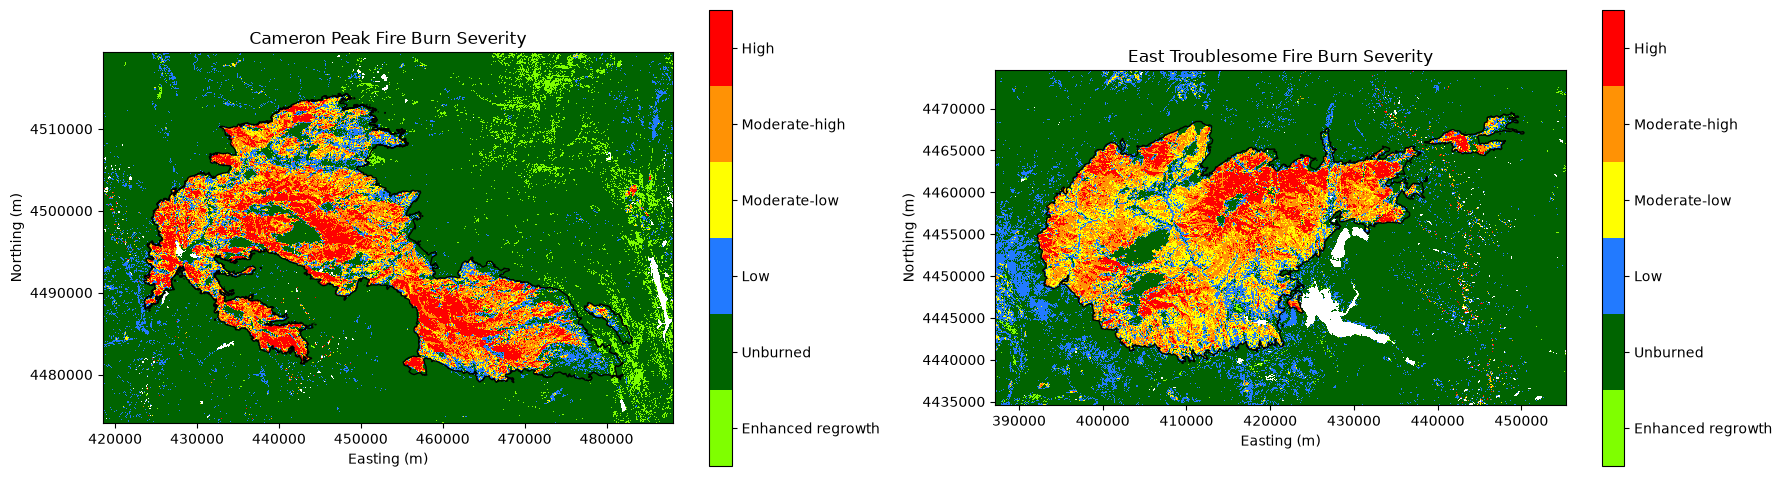

In [14]:
### colors for the class numbers 1 to 6
class_cmap = ListedColormap([class_colors[name] for name in class_names])

### plot the burn severity classes for both fires
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for ax, fire in zip(axes, fire_keys):

    ### plot the classes (0 is no data)
    classes_da = severity_classes[fire]
    classes_plot = classes_da.where(classes_da > 0).plot(ax=ax, cmap=class_cmap, vmin=0.5, vmax=len(class_names) + 0.5, cbar_kwargs={"shrink": 0.8})
    classes_plot.colorbar.set_ticks(range(1, len(class_names) + 1))
    classes_plot.colorbar.set_ticklabels(class_names)
    classes_plot.colorbar.set_label("")

    ### add the fire perimeter
    perimeters_utm[perimeters_utm["fire"] == fire].boundary.plot(ax=ax, color="black", linewidth=1)

    ax.set_aspect("equal")
    ax.ticklabel_format(style="plain")
    ax.set_title(fire.replace("_", " ").title() + " Fire Burn Severity")
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")

plt.tight_layout()
plt.show()

Figure 3: Key and Benson burn severity classes for each study area, with the NIFC perimeter in black.

### Area in each class
Areas are counted inside each NIFC perimeter. Percents are of the mapped area, which leaves out the few pixels with no clear looks in 2019 or 2021.

In [15]:
### area of each class inside the perimeters
area_rows = []

for fire in fire_keys:
    classes_values = severity_classes[fire].values[inside_masks[fire]]
    mapped_pixels = (classes_values > 0).sum()

    for number, name in enumerate(class_names, start=1):
        pixels = (classes_values == number).sum()
        area_rows.append({
            "fire": fire,
            "class": name,
            "acres": pixels * cell_size**2 / m2_per_acre,
            "percent": pixels / mapped_pixels * 100,
        })

area_df = pd.DataFrame(area_rows)

### acres and percent of each fire in each class
area_df.pivot_table(index="class", columns="fire", values=["acres", "percent"], sort=False).round(1)

acres                       percent                 
fire              cameron_peak east_troublesome cameron_peak east_troublesome
class                                                                        
Enhanced regrowth        888.2            245.7          0.4              0.1
Unburned               34519.7          21751.3         16.6             11.2
Low                    36539.5          30871.5         17.5             16.0
Moderate-low           30273.7          44958.7         14.5             23.2
Moderate-high          53140.4          59832.2         25.5             30.9
High                   52930.2          35737.5         25.4             18.5

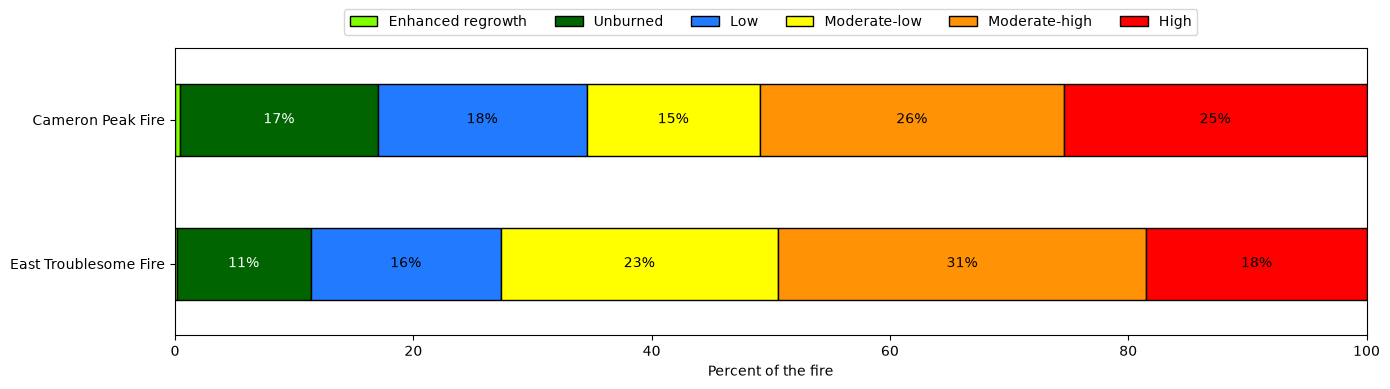

In [16]:
### percent of each fire in each class
percent_df = area_df.pivot_table(index="fire", columns="class", values="percent", sort=False)[class_names]
percent_df.index = [fire.replace("_", " ").title() + " Fire" for fire in percent_df.index]

### stacked bar of the classes for each fire
fig, ax = plt.subplots(figsize=(14, 4))
percent_df.plot(kind="barh", stacked=True, color=[class_colors[name] for name in class_names], edgecolor="black", ax=ax)

### write the percent in the classes wide enough to fit it
for bars, name in zip(ax.containers, class_names):
    labels = [str(round(width)) + "%" if width >= 4 else "" for width in bars.datavalues]
    ax.bar_label(bars, labels=labels, label_type="center", color="white" if name == "Unburned" else "black")

### Cameron Peak on top
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Percent of the fire")
ax.legend(title="", ncol=6, loc="lower center", bbox_to_anchor=(0.5, 1.02))

plt.tight_layout()
plt.show()

Figure 4: Percent of each fire in each Key and Benson class.

# 4. Save the Results
Each fire gets a folder in data/severity with its dNBR and burn severity classes, and two tables are saved for both fires: the class numbers, names, and colors, and the area in each class.

In [17]:
### save dNBR and the burn severity classes for both fires
for fire in fire_keys:
    fire_severity_dir = os.path.join(severity_dir, fire)
    os.makedirs(fire_severity_dir, exist_ok=True)

    ### dNBR (NaN is no data)
    dnbr_path = os.path.join(fire_severity_dir, fire + "_dnbr.tif")
    dnbr[fire].rio.write_crs(utm_crs).rio.write_nodata(np.nan).rio.to_raster(dnbr_path, compress="deflate")

    ### burn severity classes (0 is no data)
    classes_path = os.path.join(fire_severity_dir, fire + "_severity_classes.tif")
    severity_classes[fire].rio.write_crs(utm_crs).rio.write_nodata(0).rio.to_raster(classes_path, compress="deflate")

    print("Saved " + fire + " results to:", fire_severity_dir)

Saved cameron_peak results to: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\severity\cameron_peak
Saved east_troublesome results to: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\severity\east_troublesome


In [18]:
### make a table of the class numbers, names, thresholds, and colors
severity_classes_df = pd.DataFrame({
    "number": range(1, len(kb_classes) + 1),
    "class": class_names,
    "starts_at": starts,
    "color": [class_colors[name] for name in class_names],
})

### save the class table and the area table
classes_path = os.path.join(severity_dir, "severity_classes.csv")
severity_classes_df.to_csv(classes_path, index=False)

area_path = os.path.join(severity_dir, "severity_area.csv")
area_df.to_csv(area_path, index=False)

print("Saved class table to:", classes_path)
print("Saved area table to:", area_path)

Saved class table to: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\severity\severity_classes.csv
Saved area table to: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\severity\severity_area.csv


# 5. Summary
About half of each fire burned at moderate-high or high severity:
- Cameron Peak: 25% burned at high severity (52,930 acres) and 26% at moderate-high (53,140 acres). Most of the rest burned at low or moderate-low severity, and 17% was unburned
- East Troublesome: 18% burned at high severity (35,738 acres) and 31% at moderate-high (59,832 acres). 23% burned at moderate-low severity, more than at Cameron Peak, and 11% was unburned

Cameron Peak had more high severity, and East Troublesome had more moderate severity. The Key and Benson thresholds are the same for every fire, so the two fires can be compared directly. 03_mtbs_comparison finds that this map has less high severity than MTBS, so these high severity areas are on the low side.

# Universal Calls for the Burn Severity Data
Copy this cell into the analysis notebooks, after the Universal Calls cell from 01_data_download, to load the burn severity results saved here.

In [19]:
### BURN SEVERITY
severity_dir = os.path.join(data_dir, 'severity')

### Key and Benson class numbers, names, thresholds, and colors
severity_classes_df = pd.read_csv(os.path.join(severity_dir, 'severity_classes.csv'))

### acres and percent of each fire in each class
severity_area_df = pd.read_csv(os.path.join(severity_dir, 'severity_area.csv'))

### dNBR and burn severity classes for each fire, e.g. dnbr_paths["cameron_peak"]
dnbr_paths = {}
severity_class_paths = {}
for fire in fire_keys:
    dnbr_paths[fire] = os.path.join(severity_dir, fire, fire + '_dnbr.tif')
    severity_class_paths[fire] = os.path.join(severity_dir, fire, fire + '_severity_classes.tif')

# Citations
- Key, C. H., & Benson, N. C. (2006). Landscape assessment (LA): Sampling and analysis methods. In D. C. Lutes et al. (Eds.), *FIREMON: Fire effects monitoring and inventory system* (Gen. Tech. Rep. RMRS-GTR-164-CD, pp. LA-1-LA-55). USDA Forest Service, Rocky Mountain Research Station.